# kNN и ODIN

**Задания 4 и 5, стр. 69.** Распознавание бинарных и полутоновых растров при равномерном и неравномерном шуме; сравнение мер близости и значений $k$; поиск выбросов методом ближайших соседей и ODIN.

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.datasets import load_digits

rng = np.random.default_rng(42)
K = [1, 3, 5, 7]
metrics = ['euclidean', 'sq_euclidean', 'manhattan', 'weighted', 'chebyshev']

## 1. Эталоны и шум

Используется встроенный датасет `sklearn.datasets.load_digits`: 1797 рукописных цифр $8\times8$. Исходная яркость нормируется в $[0,1]$, бинарная версия получается порогом 0.5. Равномерный шум одинаков во всех позициях; при неравномерном вероятность изменения растёт слева направо и сверху вниз при той же средней интенсивности.

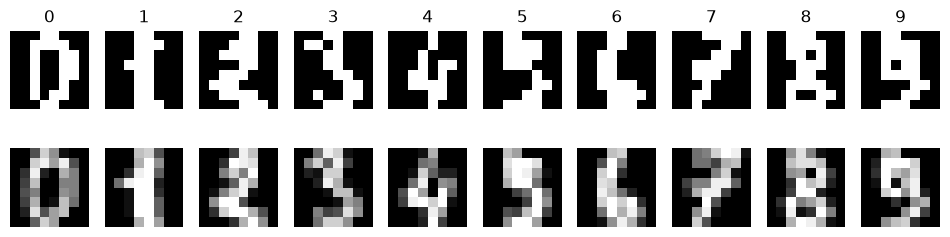

In [19]:
digits = load_digits()
gray, y = digits.images / 16, digits.target
binary = (gray >= .5).astype(float)
train_idx, test_idx = [], []
for c in range(10):
    ids = np.where(y == c)[0]
    rng.shuffle(ids)
    train_idx.extend(ids[:60])
    test_idx.extend(ids[60:100])
train_idx, test_idx = np.array(train_idx), np.array(test_idx)


def noise(img, p, delta, uniform, is_binary):
    if uniform:
        q = np.full((8, 8), p)
    else:
        q = np.clip(p * np.add.outer(np.arange(8), np.arange(8)) / 7, 0, 1)

    mask = rng.random((8, 8)) < q
    if is_binary:
        return np.where(mask, 1 - img, img)

    return np.clip(img + mask * rng.uniform(-delta, delta, (8, 8)), 0, 1)


def noisy_set(images, ids, p, delta, uniform, is_binary):
    X = [noise(images[i], p, delta, uniform, is_binary).ravel() for i in ids]
    return np.array(X), y[ids]


fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for d in range(10):
    i = np.where(y == d)[0][0]
    ax[0, d].imshow(binary[i], cmap='gray', vmin=0, vmax=1)
    ax[1, d].imshow(gray[i], cmap='gray', vmin=0, vmax=1)
    ax[0, d].set_title(d)
    ax[0, d].axis('off')
    ax[1, d].axis('off')
ax[0, 0].set_ylabel('binary')
ax[1, 0].set_ylabel('gray')
plt.show()

## 2. kNN
Напишите программу для распознавания растровых изображений, используя метод ближайшего соседа. Реализуйте программно равномерное и неравномерное зашумление изображений и сравните процент распознавания для используемых норм в случаях распознавания растровых бинарных изображений и изображений в градациях серого цвета для различных 𝑘. В качестве мер близости используйте предложенные выше и сравните результаты их применения (используются евклидово расстояние, его квадрат, манхэттенское, взвешенное евклидово и расстояние Чебышёва)

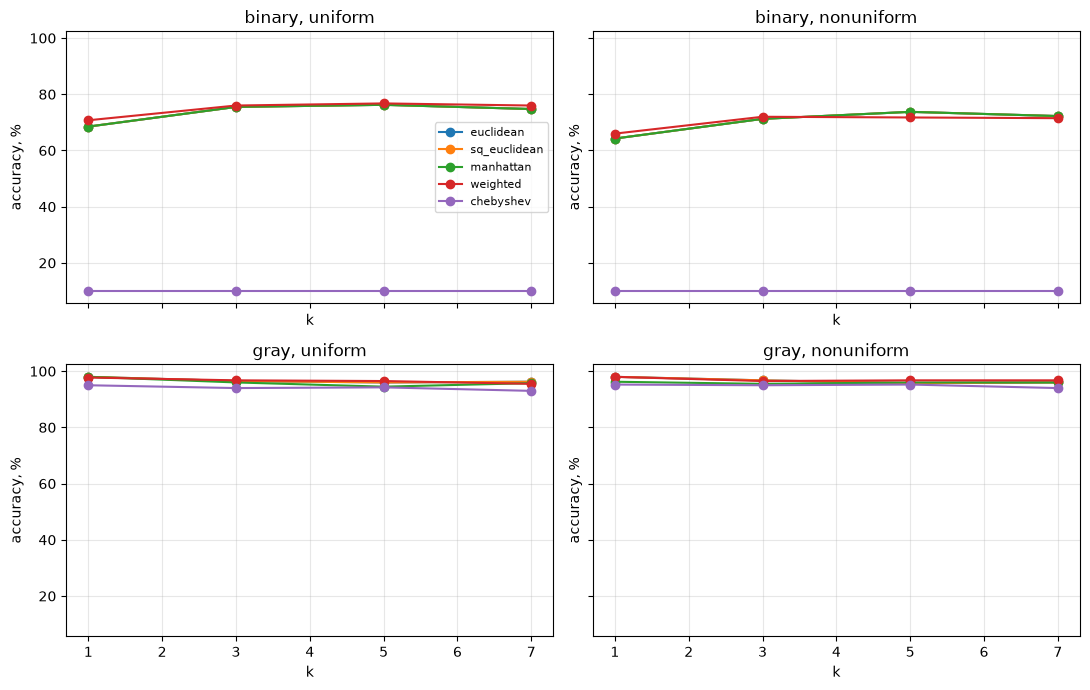

| Изображение | Шум | Лучшая точность | Метрика | k |
|---|---|---:|---|---:|
| binary | uniform | 76.8% | weighted | 5 |
| binary | nonuniform | 73.8% | euclidean | 5 |
| gray | uniform | 98.0% | euclidean | 1 |
| gray | nonuniform | 98.0% | euclidean | 1 |


In [20]:
def distance(A, B, metric, weights=None):
    # differences[i, j] — разность признаков i-го объекта A и j-го объекта B
    differences = A[:, np.newaxis, :] - B[np.newaxis, :, :]
    if metric == 'euclidean':
        return np.sqrt(np.sum(differences ** 2, axis=2))
    if metric == 'sq_euclidean':
        return np.sum(differences ** 2, axis=2)
    if metric == 'manhattan':
        return np.sum(np.abs(differences), axis=2)
    if metric == 'weighted':
        return np.sqrt(np.sum(weights * differences ** 2, axis=2))
    if metric == 'chebyshev':
        return np.max(np.abs(differences), axis=2)


def predict(D, y, k):
    predictions = []
    for distances_to_train in D:
        neighbor_indices = np.argsort(distances_to_train)[:k]
        neighbor_labels = y[neighbor_indices]
        votes = np.bincount(neighbor_labels, minlength=10)
        predicted_class = np.argmax(votes)
        predictions.append(predicted_class)
    return np.array(predictions)


settings = [('binary', 'uniform', binary, True, .03, .15, 1),
            ('binary', 'nonuniform', binary, True, .03, .15, 1),
            ('gray', 'uniform', gray, False, .10, .30, .35),
            ('gray', 'nonuniform', gray, False, .10, .30, .35)]

results = []
for kind, mode, images, is_binary, p_train, p_test, delta in settings:
    uniform = mode == 'uniform'
    Xtr, ytr = noisy_set(images, train_idx, p_train, delta / 2, uniform, is_binary)
    Xte, yte = noisy_set(images, test_idx, p_test, delta, uniform, is_binary)
    weights = .1 + Xtr.var(axis=0)
    for metric in metrics:
        Dist = distance(Xte, Xtr, metric, weights)
        for k in K: results.append((kind, mode, metric, k, 100 * np.mean(predict(Dist, ytr, k) == yte)))

fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for a, (kind, mode, *_) in zip(ax.ravel(), settings):
    for metric in metrics:
        r = [x for x in results if x[:3] == (kind, mode, metric)]
        a.plot(K, [x[4] for x in r], marker='o', label=metric)
    a.set_title(f'{kind}, {mode}')
    a.grid(alpha=.3)
    a.set_xlabel('k')
    a.set_ylabel('accuracy, %')
ax[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

best = [max((x for x in results if x[:2] == s[:2]), key=lambda x: x[4]) for s in settings]
table = '| Изображение | Шум | Лучшая точность | Метрика | k |\n|---|---|---:|---|---:|\n'
for kind, mode, metric, k, acc in best: table += f'| {kind} | {mode} | {acc:.1f}% | {metric} | {k} |\n'
display(Markdown(table))

## 3. Выбросы kNN и ODIN
 Сгенерируйте обучающую выборку для решения задачи распознавания растровых изображений, содержащую выбросы типа 0. Назовём выбросы этого типа выбросами типа 1, если они не распознаются как выбросы с помощью метода ближайшего соседа, выбросами типа 2 — выбросы типа 0, которые не распознаются с помощью метода ODIN. Реализуйте оба подхода к идентификации выбросов. Cравните результаты их работы.

В полутоновую обучающую выборку добавляются известные **выбросы типа 0**: 15 обычных изображений с неверной меткой и 15 растров с грубым единичным сбоем датчика (яркость одного пикселя выходит за диапазон). kNN-детектор исключает проверяемый объект и отмечает его, если соседи предсказывают другой класс. Пропущенные им выбросы типа 0 — **тип 1**. ODIN строит ориентированный kNN-граф; объект считается выбросом при нулевой входящей степени. Пропущенные ODIN выбросы типа 0 — **тип 2**.

| Метод | TP | FP | FN | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|
| kNN | 27 | 11 | 3 | 0.71 | 0.90 | 0.79 |
| ODIN | 15 | 5 | 15 | 0.75 | 0.50 | 0.60 |


Пропущено kNN (тип 1): 3
Пропущено ODIN (тип 2): 15
type 0      : kNN 15/15, ODIN  0/15
type 1      : kNN 12/15, ODIN 15/15


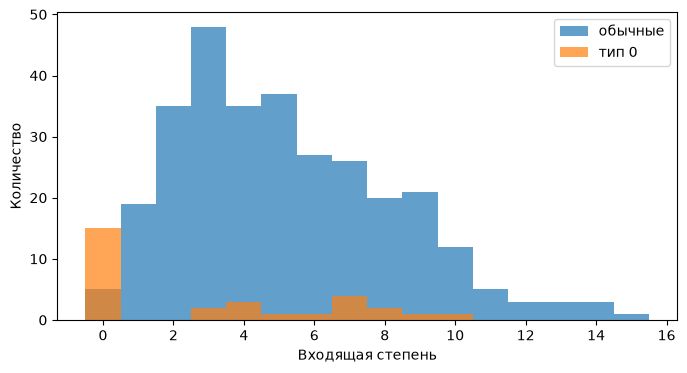

In [21]:
small_idx = np.concatenate([train_idx[c * 60:c * 60 + 30] for c in range(10)])
X, labels = noisy_set(gray, small_idx, .10, .18, True, False)
n, k = 15, 5
idx = rng.choice(len(X), n, replace=False)
bad = np.zeros((n, 64))
bad[np.arange(n), np.argsort(X.var(axis=0))[-n:]] = 10
X0 = np.vstack([X, X[idx], bad])
y0 = np.r_[labels, (labels[idx] + rng.integers(1, 10, n)) % 10, rng.integers(0, 10, n)]
truth = np.r_[np.zeros(len(X), bool), np.ones(2 * n, bool)]
subtype = np.array(['normal'] * len(X) + ['type 0'] * n + ['type 1'] * n)

D = distance(X0, X0, 'euclidean')
np.fill_diagonal(D, np.inf)
neighbors = np.argpartition(D, k - 1, axis=1)[:, :k]
knn_out = np.array([np.bincount(y0[row], minlength=10).argmax() for row in neighbors]) != y0
indegree = np.bincount(neighbors.ravel(), minlength=len(X0))
odin_out = indegree == 0


def score(found):
    tp, fp, fn = (truth & found).sum(), (~truth & found).sum(), (truth & ~found).sum()
    p, r = tp / (tp + fp) if tp + fp else 0, tp / (tp + fn)
    return int(tp), int(fp), int(fn), p, r, 2 * p * r / (p + r) if p + r else 0


rows = [('kNN', *score(knn_out)), ('ODIN', *score(odin_out))]
table = '| Метод | TP | FP | FN | Precision | Recall | F1 |\n|---|---:|---:|---:|---:|---:|---:|\n'
for m, tp, fp, fn, p, r, f1 in rows: table += f'| {m} | {tp} | {fp} | {fn} | {p:.2f} | {r:.2f} | {f1:.2f} |\n'
display(Markdown(table))
print('Пропущено kNN (тип 1):', int((truth & ~knn_out).sum()))
print('Пропущено ODIN (тип 2):', int((truth & ~odin_out).sum()))
for name in ['type 0', 'type 1']:
    m = subtype == name
    print(f'{name:12s}: kNN {knn_out[m].sum():2d}/{m.sum()}, ODIN {odin_out[m].sum():2d}/{m.sum()}')

plt.figure(figsize=(8, 4))
plt.hist(indegree[subtype == 'normal'], bins=np.arange(indegree.max() + 2) - .5, alpha=.7, label='обычные')
plt.hist(indegree[truth], bins=np.arange(indegree.max() + 2) - .5, alpha=.7, label='тип 0')
plt.xlabel('Входящая степень')
plt.ylabel('Количество')
plt.legend()
plt.show()

## Выводы

1. Реализован kNN для бинарных и полутоновых растров с пятью мерами близости и двумя видами шума.
2. Евклидово расстояние и его квадрат дают одинаковый порядок соседей. Для бинарных растров $L_1$ также эквивалентна им, так как квадрат и модуль разности бинарных пикселей совпадают. Расстояние Чебышёва для бинарных растров малоинформативно: почти все различные изображения находятся на расстоянии 1.
3. Оптимальное $k$ зависит от шума и метрики; несколько соседей обычно устойчивее одного, но слишком большое $k$ смешивает классы.
4. kNN-детектор использует метки и хорошо находит ошибки разметки. ODIN не использует метки и ищет геометрически изолированные точки, поэтому методы обнаруживают разные виды аномалий и дополняют друг друга.